# 09 — Unsupervised Article Segmentation

## What this notebook does

We explore whether H&M articles with similar **observed historical behaviour** form useful descriptive groups. The unit is one article, not one transaction or one article-week. The published `article_clustering.csv.gz` was built only from the chronological training partition; future sales targets, validation and test are not used to construct the groups.

## Objectives

- Audit the article-level population, source publication and missing values.
- Prepare comparable numeric history and price variables without letting extreme sales dominate distances.
- Use a PCA biplot combining article scores and numbered variable directions; report explained variance and use t-SNE as a second visual exploration.
- Compare K-means and hierarchical clustering on the **same reproducible sample**.
- Fit the selected K-means configuration to all training articles, assess seed stability, and describe group profiles.
- Distinguish descriptive associations from predictions or causal explanations.

## Sections

0. Existing conceptual diagrams (optional to rerun)
1. Data publication and article population
2. Numeric representation
3. PCA projection and loadings
4. t-SNE projection
5. K-means versus hierarchical clustering
6. Full-population clusters and stability
7. Profiles, limitations and saved summary

**Run order:** keep the two existing diagram cells if you want to recreate those figures on this computer. The data analysis begins at section 1. Run its new code cells from top to bottom. Do not interpret PCA or t-SNE coordinates as a test of cluster validity.
**Figure style.** Analysis figures follow the reference report style: Latin Modern, white background, dark blue and orange, large readable text, and SVG/PNG export. Multi-category point clouds additionally use green, red and other distinct colours; the remaining figures retain blue and orange. Rerun the figure cells after the setup cell to replace the previously saved images.

**Figure notes.** The source and sample definitions are documented in the surrounding text and saved metrics, rather than printed inside the figures.


## 0. Existing conceptual diagrams

The following two cells are the diagrams already present in your local notebook. They use your local Latin Modern font and `imagenes` folder. Their saved outputs are preserved. They are illustrations, not results of clustering; the reproducible analysis starts after them.

Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\analytical_workflow_repository.pdf
Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\analytical_workflow_repository.svg
Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\analytical_workflow_repository.png


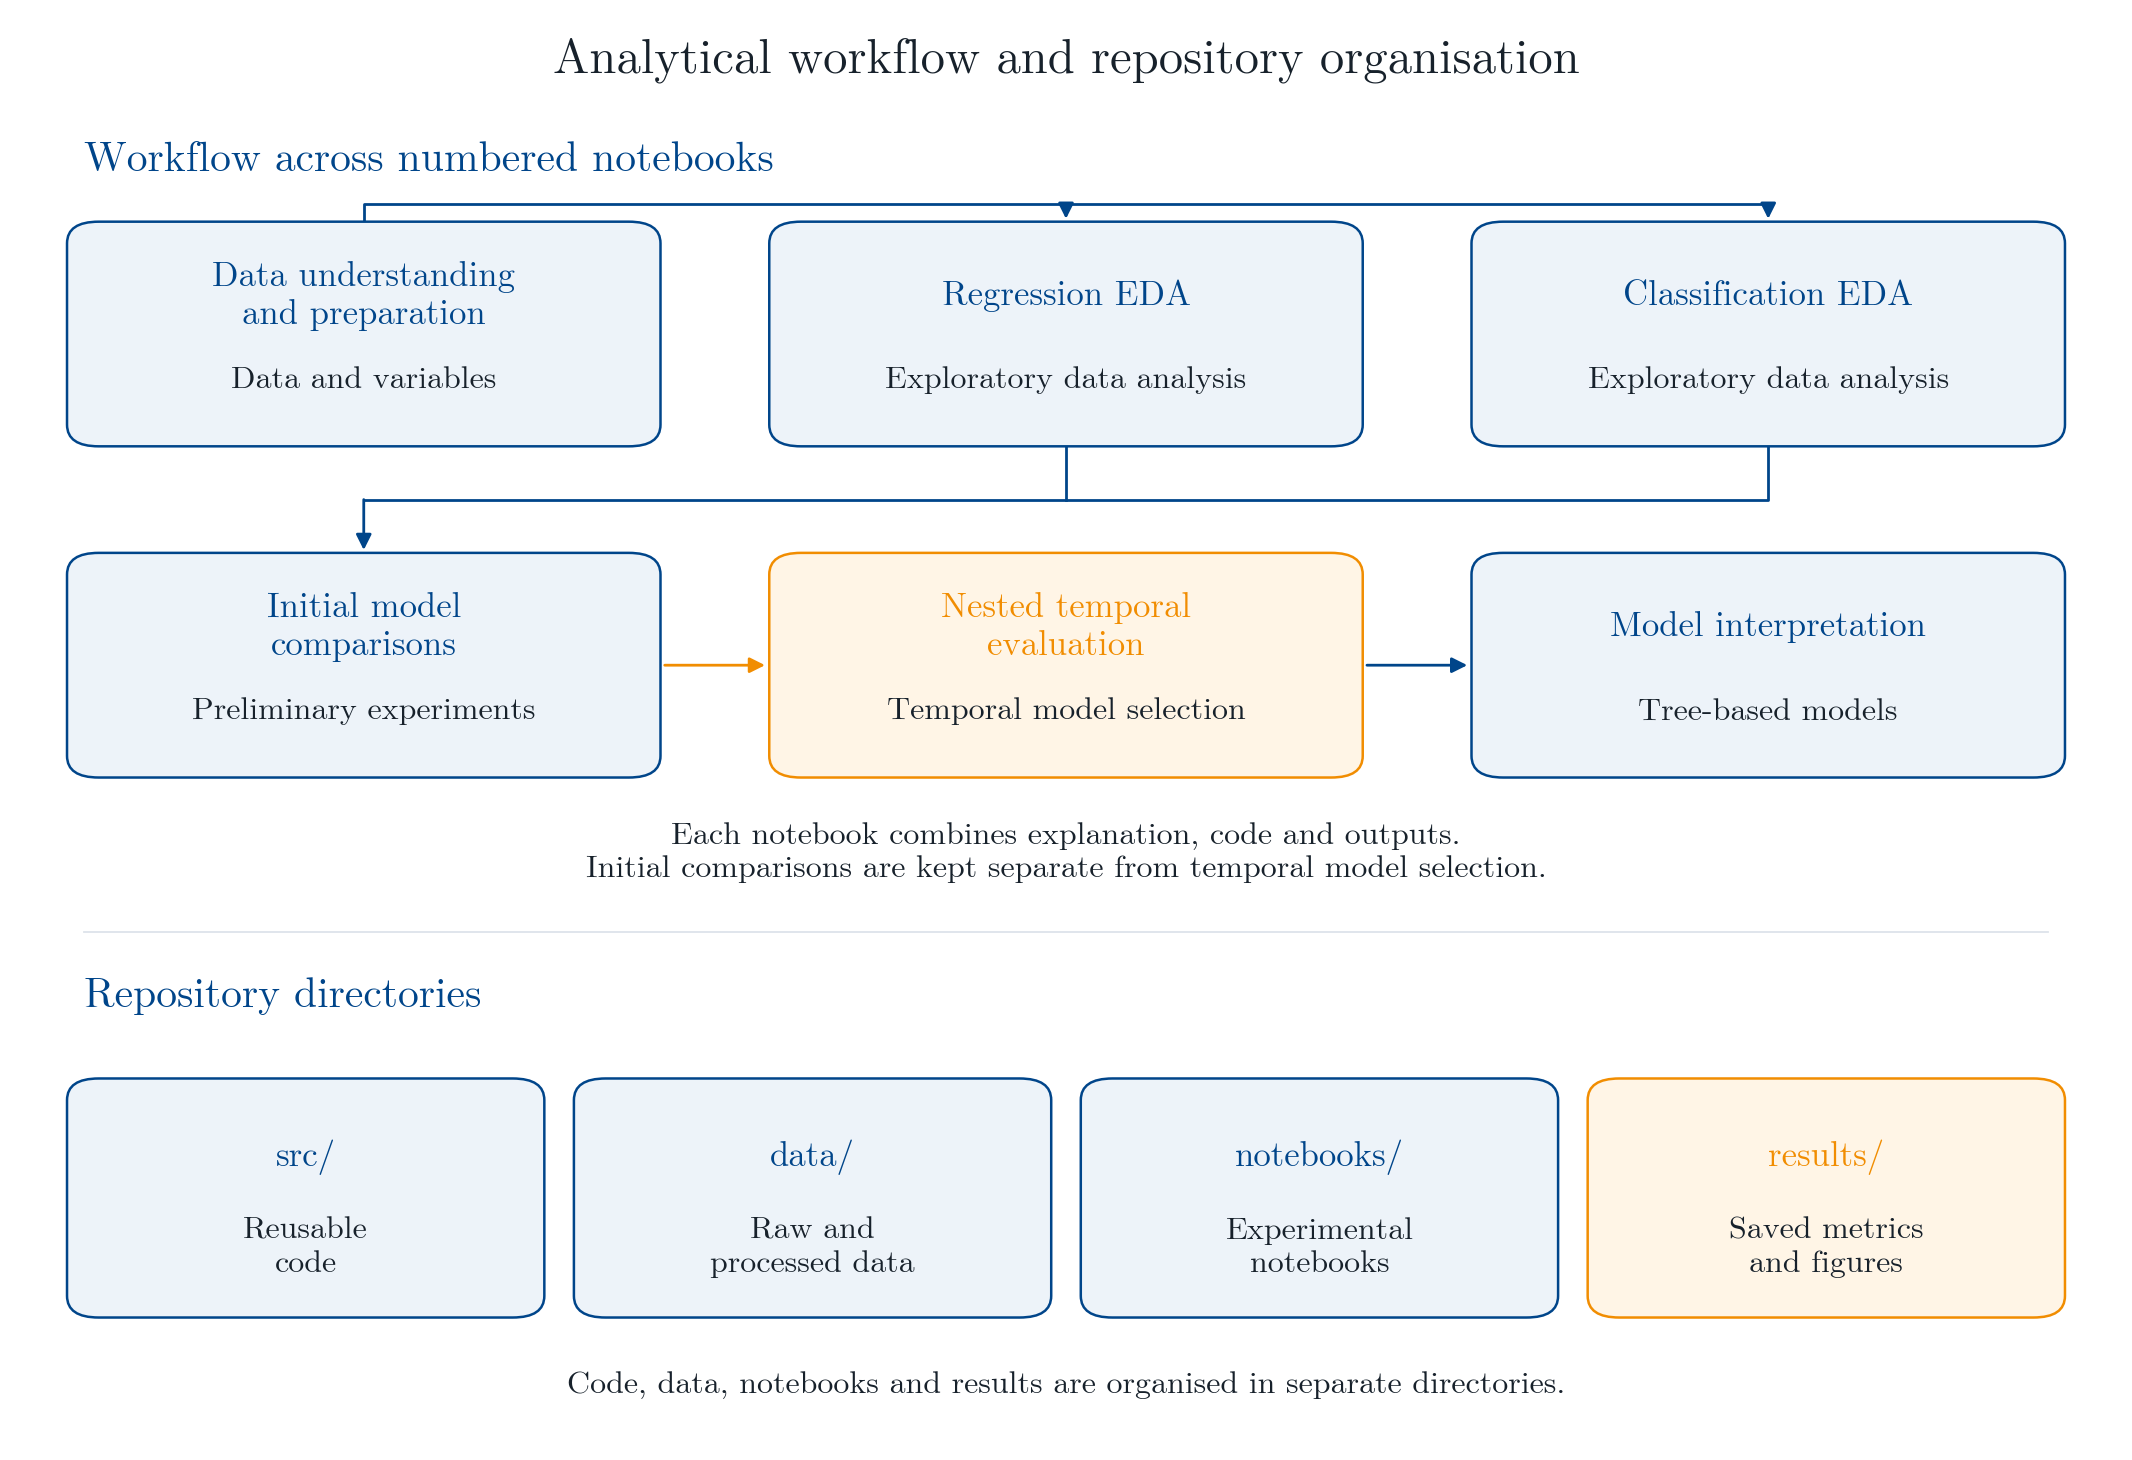

In [65]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch


# 1. CONFIGURATION
carpeta = Path(r"C:\Iratxe\UPM\prdl y mllb\imagenes")
formatos = ["pdf", "svg", "png"]

font_path = Path(
    r"C:\Users\irfer\AppData\Local\Microsoft\Windows\Fonts"
    r"\lmroman10-regular.ttf"
)

if not font_path.is_file():
    raise FileNotFoundError(f"Font not found:\n{font_path}")

custom_font = FontProperties(fname=str(font_path))

# Colours extracted from the supplied ETSIT-UPM image.
BLUE = "#00458A"
ORANGE = "#F18D01"

INK = "#17212B"
GRID = "#DDE3EA"
LIGHT_BLUE = "#EDF3F9"
LIGHT_ORANGE = "#FFF5E6"

TITLE_SIZE = 35
SECTION_SIZE = 30
BOX_TITLE_SIZE = 25
BODY_SIZE = 23
NOTE_SIZE = 23

plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# 2. DRAWING FUNCTIONS
def add_text(
    ax, x, y, content,
    size=BODY_SIZE,
    colour=INK,
    bold=False,
    ha="center",
):
    return ax.text(
        x, y, content,
        fontproperties=custom_font,
        fontsize=size,
        fontweight="bold" if bold else "normal",
        color=colour,
        ha=ha,
        va="center",
        linespacing=1.25,
        zorder=4,
    )


def add_box(
    ax, x, y, width, height,
    title, description,
    colour=BLUE,
    background=LIGHT_BLUE,
):
    patch = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.008,rounding_size=0.015",
        linewidth=1.8,
        edgecolor=colour,
        facecolor=background,
        zorder=3,
    )
    ax.add_patch(patch)

    add_text(
        ax,
        x + width / 2,
        y + height * 0.69,
        title,
        size=BOX_TITLE_SIZE,
        colour=colour,
        bold=True,
    )

    add_text(
        ax,
        x + width / 2,
        y + height * 0.27,
        description,
        size=BODY_SIZE,
    )


def add_arrow(ax, start, end, colour=BLUE):
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            arrowstyle="-|>",
            mutation_scale=23,
            linewidth=2,
            color=colour,
            shrinkA=0,
            shrinkB=0,
            zorder=2,
        )
    )


def save_figure(fig, name):
    carpeta.mkdir(parents=True, exist_ok=True)

    for formato in formatos:
        ruta = carpeta / f"{name}.{formato}"

        fig.savefig(
            ruta,
            format=formato,
            dpi=300,
            facecolor="white",
            transparent=False,
            bbox_inches="tight",
            pad_inches=0.25,
        )

        print(f"Saved: {ruta}")


# 3. CANVAS
fig, ax = plt.subplots(figsize=(22, 15))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

add_text(
    ax, 0.5, 0.965,
    "Analytical workflow and repository organisation",
    size=TITLE_SIZE,
    bold=True,
)

add_text(
    ax, 0.035, 0.895,
    "Workflow across numbered notebooks",
    size=SECTION_SIZE,
    colour=BLUE,
    bold=True,
    ha="left",
)


# 4. ANALYTICAL WORKFLOW
# Two rows provide space for larger text.
width = 0.265
height = 0.14

x_left = 0.035
x_middle = 0.3675
x_right = 0.70

y_top = 0.705
y_bottom = 0.475

# First row: data preparation followed by separate EDA branches.
add_box(
    ax, x_left, y_top, width, height,
    "Data understanding\nand preparation",
    "Data and variables",
)

add_box(
    ax, x_middle, y_top, width, height,
    "Regression EDA",
    "Exploratory data analysis",
)

add_box(
    ax, x_right, y_top, width, height,
    "Classification EDA",
    "Exploratory data analysis",
)

# Branch above the EDA boxes.
branch_y = 0.865
source_x = x_left + width / 2
regression_x = x_middle + width / 2
classification_x = x_right + width / 2

ax.plot(
    [source_x, source_x, classification_x],
    [y_top + height + 0.008, branch_y, branch_y],
    color=BLUE,
    linewidth=2,
    zorder=2,
)

add_arrow(
    ax,
    (regression_x, branch_y),
    (regression_x, y_top + height + 0.01),
)
add_arrow(
    ax,
    (classification_x, branch_y),
    (classification_x, y_top + height + 0.01),
)

# Second row: comparisons, nested evaluation and interpretation.
add_box(
    ax, x_left, y_bottom, width, height,
    "Initial model\ncomparisons",
    "Preliminary experiments",
)

add_box(
    ax, x_middle, y_bottom, width, height,
    "Nested temporal\nevaluation",
    "Temporal model selection",
    colour=ORANGE,
    background=LIGHT_ORANGE,
)

add_box(
    ax, x_right, y_bottom, width, height,
    "Model interpretation",
    "Tree-based models",
)

# Combine the two EDA branches and feed the initial comparisons.
merge_y = 0.66
comparison_x = x_left + width / 2

ax.plot(
    [regression_x, regression_x],
    [y_top - 0.008, merge_y],
    color=BLUE,
    linewidth=2,
    zorder=2,
)
ax.plot(
    [classification_x, classification_x, comparison_x],
    [y_top - 0.008, merge_y, merge_y],
    color=BLUE,
    linewidth=2,
    zorder=2,
)

add_arrow(
    ax,
    (comparison_x, merge_y),
    (comparison_x, y_bottom + height + 0.01),
)

# Subsequent stages.
centre_y = y_bottom + height / 2

add_arrow(
    ax,
    (x_left + width + 0.01, centre_y),
    (x_middle - 0.01, centre_y),
    colour=ORANGE,
)
add_arrow(
    ax,
    (x_middle + width + 0.01, centre_y),
    (x_right - 0.01, centre_y),
)

add_text(
    ax, 0.5, 0.415,
    "Each notebook combines explanation, code and outputs.\n"
    "Initial comparisons are kept separate from temporal model selection.",
    size=NOTE_SIZE,
)


# 5. REPOSITORY ORGANISATION
ax.plot(
    [0.035, 0.965],
    [0.36, 0.36],
    color=GRID,
    linewidth=1.3,
)

add_text(
    ax, 0.035, 0.315,
    "Repository directories",
    size=SECTION_SIZE,
    colour=BLUE,
    bold=True,
    ha="left",
)

directory_width = 0.21
directory_height = 0.15
directory_y = 0.10

directories = [
    (0.035, "src/", "Reusable\ncode"),
    (0.275, "data/", "Raw and\nprocessed data"),
    (0.515, "notebooks/", "Experimental\nnotebooks"),
    (0.755, "results/", "Saved metrics\nand figures"),
]

for x, title, description in directories:
    is_results = title == "results/"

    add_box(
        ax,
        x, directory_y,
        directory_width, directory_height,
        title,
        description,
        colour=ORANGE if is_results else BLUE,
        background=LIGHT_ORANGE if is_results else LIGHT_BLUE,
    )

add_text(
    ax, 0.5, 0.045,
    "Code, data, notebooks and results are organised in separate directories.",
    size=NOTE_SIZE,
)


# 6. EXPORT
fig.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.98,
    bottom=0.02,
)

save_figure(fig, "analytical_workflow_repository")
plt.show()

Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\data_combination.pdf
Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\data_combination.svg
Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\data_combination.png


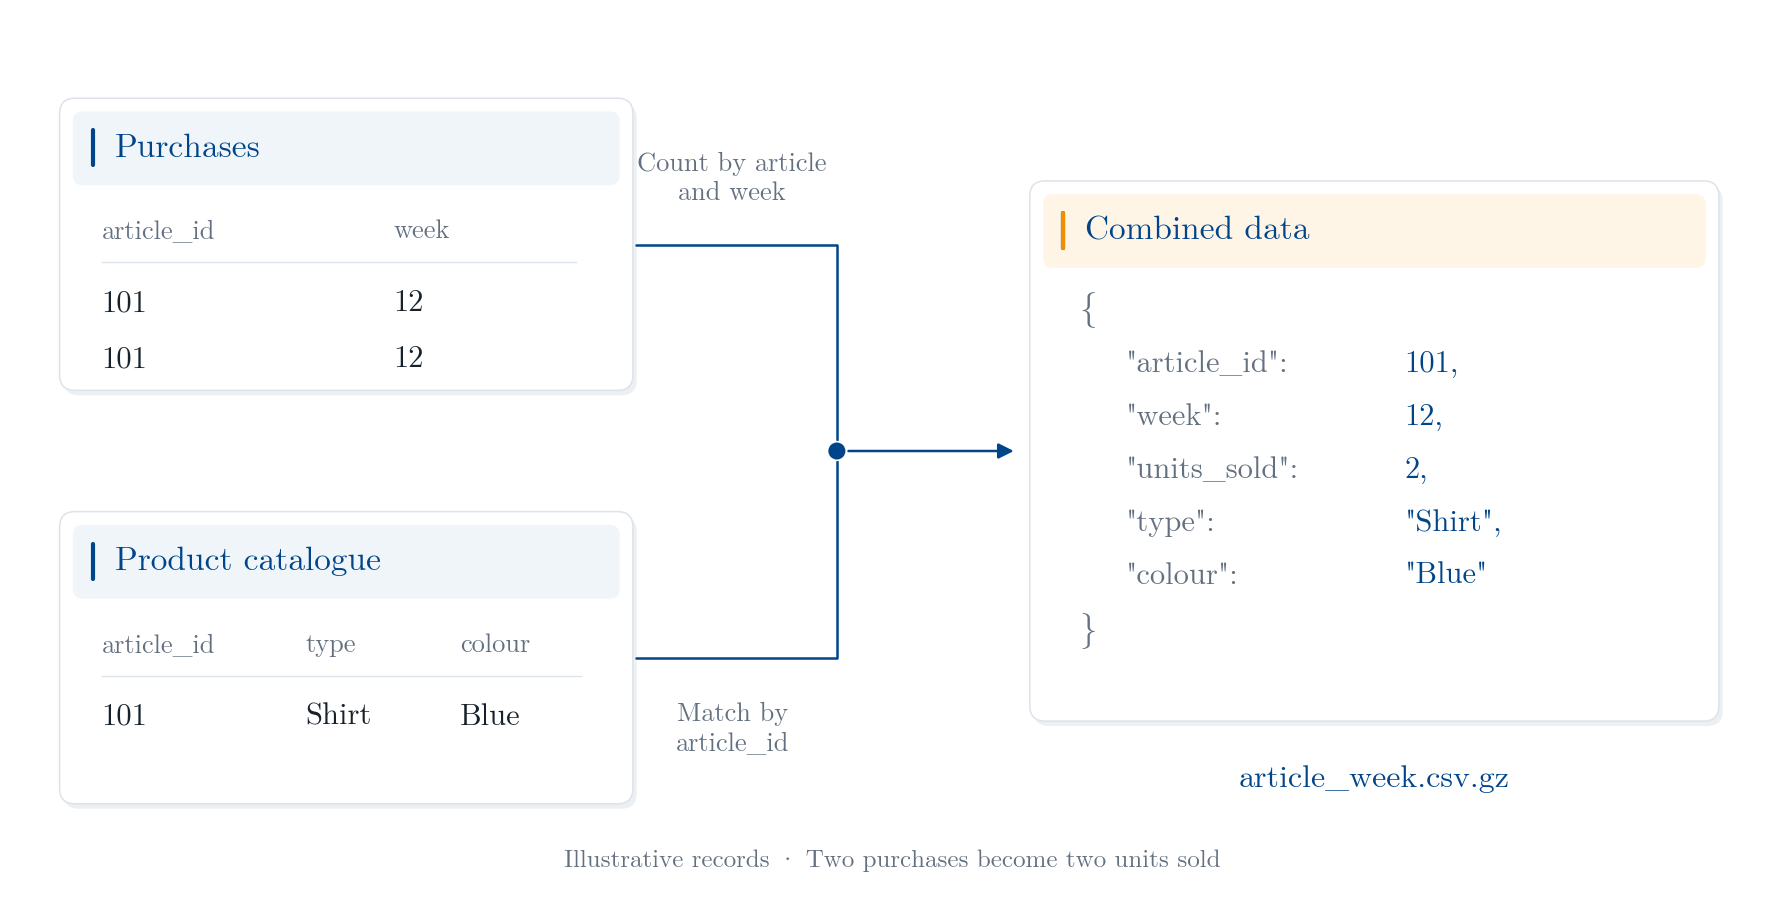

In [66]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle


# CONFIGURATION
carpeta = Path(r"C:\Iratxe\UPM\prdl y mllb\imagenes")

font_path = Path(
    r"C:\Users\irfer\AppData\Local\Microsoft\Windows\Fonts"
    r"\lmroman10-regular.ttf"
)
if not font_path.is_file():
    raise FileNotFoundError(f"Font not found:\n{font_path}")

font = FontProperties(fname=str(font_path))

BLUE = "#00458A"
ORANGE = "#F18D01"
INK = "#17212B"
MUTED = "#637080"
LINE = "#DDE3EA"
PALE_BLUE = "#F0F5FA"
PALE_ORANGE = "#FFF5E7"

plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(18, 9))
fig.patch.set_facecolor("white")
ax.set(xlim=(0, 16), ylim=(0, 8))
ax.set_aspect("equal")
ax.axis("off")


# DRAWING FUNCTIONS
def text(x, y, value, size=20, colour=INK, ha="left"):
    ax.text(
        x, y, value,
        fontproperties=font,
        fontsize=size,
        color=colour,
        ha=ha,
        va="center",
        linespacing=1.3,
        zorder=5,
    )


def card(x, y, width, height, title, accent, tint):
    # Subtle shadow.
    ax.add_patch(
        FancyBboxPatch(
            (x + 0.035, y - 0.045), width, height,
            boxstyle="round,pad=0,rounding_size=0.14",
            facecolor="#EDF0F3",
            edgecolor="none",
            zorder=1,
        )
    )

    # White body.
    ax.add_patch(
        FancyBboxPatch(
            (x, y), width, height,
            boxstyle="round,pad=0,rounding_size=0.14",
            facecolor="white",
            edgecolor=LINE,
            linewidth=1.1,
            zorder=2,
        )
    )

    # Inset header.
    ax.add_patch(
        FancyBboxPatch(
            (x + 0.12, y + height - 0.79),
            width - 0.24, 0.67,
            boxstyle="round,pad=0,rounding_size=0.09",
            facecolor=tint,
            edgecolor="none",
            zorder=3,
        )
    )

    ax.plot(
        [x + 0.30, x + 0.30],
        [y + height - 0.61, y + height - 0.29],
        color=accent,
        linewidth=3,
        solid_capstyle="round",
        zorder=4,
    )

    text(
        x + 0.50, y + height - 0.45,
        title, size=24, colour=accent,
    )


def table(x, header_y, widths, headers, rows):
    """Position each cell explicitly for reliable alignment."""
    positions = [x]
    for width in widths[:-1]:
        positions.append(positions[-1] + width)

    for column_x, header in zip(positions, headers):
        text(column_x, header_y, header, size=19, colour=MUTED)

    ax.plot(
        [x, x + sum(widths)],
        [header_y - 0.28, header_y - 0.28],
        color=LINE,
        linewidth=1,
        zorder=4,
    )

    for row_number, row in enumerate(rows):
        row_y = header_y - 0.65 - row_number * 0.51

        for column_x, value in zip(positions, row):
            text(column_x, row_y, str(value), size=22)


# INPUT CARDS
card(
    0.45, 4.55, 5.2, 2.65,
    "Purchases", BLUE, PALE_BLUE,
)

table(
    0.83, 5.99,
    widths=[2.65, 1.65],
    headers=["article_id", "week"],
    rows=[
        [101, 12],
        [101, 12],
    ],
)

card(
    0.45, 0.80, 5.2, 2.65,
    "Product catalogue", BLUE, PALE_BLUE,
)

table(
    0.83, 2.24,
    widths=[1.85, 1.40, 1.10],
    headers=["article_id", "type", "colour"],
    rows=[
        [101, "Shirt", "Blue"],
    ],
)


# CONNECTIONS
# Orthogonal routes converge before entering the output.
junction_x = 7.50
junction_y = 4.00

for source_y in [5.87, 2.12]:
    ax.plot(
        [5.68, junction_x, junction_x],
        [source_y, source_y, junction_y],
        color=BLUE,
        linewidth=1.8,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=1,
    )

ax.add_patch(
    Circle(
        (junction_x, junction_y),
        radius=0.085,
        facecolor=BLUE,
        edgecolor="white",
        linewidth=1.2,
        zorder=4,
    )
)

ax.add_patch(
    FancyArrowPatch(
        (junction_x + 0.08, junction_y),
        (9.13, junction_y),
        arrowstyle="-|>",
        mutation_scale=23,
        linewidth=1.8,
        color=BLUE,
        zorder=3,
    )
)

text(
    6.55, 6.47,
    "Count by article\nand week",
    size=19, colour=MUTED, ha="center",
)

text(
    6.55, 1.48,
    "Match by\narticle_id",
    size=19, colour=MUTED, ha="center",
)


# OUTPUT CARD
card(
    9.25, 1.55, 6.25, 4.90,
    "Combined data", BLUE, PALE_ORANGE,
)

# Orange accent for the resulting file.
ax.plot(
    [9.55, 9.55],
    [5.84, 6.16],
    color=ORANGE,
    linewidth=3,
    solid_capstyle="round",
    zorder=6,
)

text(9.70, 5.28, "{", size=25, colour=MUTED)

fields = [
    ('"article_id":', "101,"),
    ('"week":', "12,"),
    ('"units_sold":', "2,"),
    ('"type":', '"Shirt",'),
    ('"colour":', '"Blue"'),
]

for index, (key, value) in enumerate(fields):
    y = 4.79 - index * 0.48

    text(10.12, y, key, size=22, colour=MUTED)
    text(12.65, y, value, size=22, colour=BLUE)

text(9.70, 2.37, "}", size=25, colour=MUTED)

text(
    12.375, 1.02,
    "article_week.csv.gz",
    size=23, colour=BLUE, ha="center",
)

text(
    8.0, 0.28,
    "Illustrative records · Two purchases become two units sold",
    size=18, colour=MUTED, ha="center",
)


# EXPORT
fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01)
carpeta.mkdir(parents=True, exist_ok=True)

for formato in ["pdf", "svg", "png"]:
    ruta = carpeta / f"data_combination.{formato}"

    fig.savefig(
        ruta,
        format=formato,
        dpi=300,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.2,
    )

    print(f"Saved: {ruta}")

plt.show()

## 1. Data publication and article population

**Code walkthrough.** Locate the project, read the published run from `CURRENT.json`, verify the clustering file checksum, and load its article-level table. The preparation pipeline created this table from **train only**. We check its recorded row count, unique article IDs and date range. No future target columns are loaded.

In [67]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "src/data/process_data.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the fashion-demand-ml project.")

processed = ROOT / "data/processed"
pointer = json.loads((processed / "CURRENT.json").read_text(encoding="utf-8"))
run_dir = (processed / pointer["run_dir"]).resolve()
if not run_dir.is_relative_to(processed.resolve()) or pointer.get("preview"):
    raise ValueError("CURRENT.json must reference a complete published run.")
summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
checksums = json.loads((run_dir / "checksums.json").read_text(encoding="utf-8"))
cluster_path = run_dir / "article_clustering.csv.gz"
digest = hashlib.sha256()
with cluster_path.open("rb") as stream:
    for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
        digest.update(block)
if digest.hexdigest() != checksums[cluster_path.name]:
    raise ValueError("The published clustering table failed its checksum check.")

articles = pd.read_csv(
    cluster_path,
    dtype={"article_id": "string"},
    parse_dates=["observation_start", "observation_end"],
)
contract = summary["clustering_definition"]
assert contract["unit"] == "article"
assert contract["source_partition"] == "train only"
assert contract["future_targets_used"] is False
assert len(articles) == contract["rows"]
assert articles["article_id"].is_unique and articles["article_id"].notna().all()
assert articles["observation_end"].max() < pd.Timestamp(
    summary["split_configuration"]["validation_start"]
)
assert not {"target_next_week_sales", "target_high_demand", "split"}.intersection(articles)

PAPER, INK, MUTED, GRID = "#FFFFFF", "#17212B", "#667085", "#DDE3EA"
BLUE, ORANGE = "#00458A", "#F18D01"  # Report / ETSIT palette.
TEAL, CORAL, VIOLET = "#168A87", "#C7654A", "#7357C8"
PALETTE = [BLUE, ORANGE, "#4D86B9", "#F5B760", "#7B8794"]
# The font used in the report figures. Fall back gracefully on other computers.
FONT_FILE = Path(r"C:\Users\irfer\AppData\Local\Microsoft\Windows\Fonts\lmroman10-regular.ttf")
if FONT_FILE.is_file():
    font_manager.fontManager.addfont(str(FONT_FILE))
    FONT = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()
else:
    available_fonts = {font.name for font in font_manager.fontManager.ttflist}
    FONT = next((name for name in ["Arial", "Liberation Sans", "DejaVu Sans"]
                 if name in available_fonts), "DejaVu Sans")
plt.rcParams.update({
    "font.family": FONT,
    "font.size": 13,
    "axes.titlesize": 19,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "figure.dpi": 110,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": PAPER,
    "axes.facecolor": PAPER,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})
FIGURE_DIR = Path(r"C:\Iratxe\UPM\prdl y mllb\imagenes")
METRIC_DIR = ROOT / "results/metrics"

def format_es(value, digits=2):
    if pd.isna(value):
        return "—"
    result = f"{value:,.{digits}f}".rstrip("0").rstrip(".") if digits else f"{value:,.0f}"
    return result.replace(",", "@").replace(".", ",").replace("@", ".")

def display_es(frame, digits=3):
    shown = frame.copy()
    for column in shown.select_dtypes(include="number"):
        precision = 0 if pd.api.types.is_integer_dtype(shown[column]) else digits
        shown[column] = shown[column].map(lambda value: format_es(value, precision))
    display(shown)

def style_axis(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=15, fontweight="bold", color=INK, labelpad=8)
    ax.set_ylabel(ylabel, fontsize=15, fontweight="bold", color=INK, labelpad=8)
    ax.tick_params(axis="both", labelsize=12)
    ax.grid(color=GRID, linewidth=.6, alpha=.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: format_es(value)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_es(value)))

def save_plot(fig, stem):
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / f"{stem}.pdf", bbox_inches="tight", facecolor=PAPER, pad_inches=.25)
    fig.savefig(FIGURE_DIR / f"{stem}.svg", bbox_inches="tight", facecolor=PAPER, pad_inches=.25)
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=300, bbox_inches="tight", facecolor=PAPER, pad_inches=.25)

print("Publication:", run_dir.name)
print("Training articles:", format_es(len(articles), 0))
print("Observed weeks:", articles["observation_start"].min().date(),
      "to", articles["observation_end"].max().date())
display_es(articles.head(3))

Publication: 20261027T145552-5a1ac59a
Training articles: 77.357
Observed weeks: 2018-12-17 to 2020-02-17


,article_id,observation_start,observation_end,article_weeks,mean_current_week_sales,median_current_week_sales,std_current_week_sales,max_current_week_sales,mean_12w_sales,mean_12w_sales_volatility,...,mean_online_share,product_code,product_type_name,product_group_name,graphical_appearance_name,colour_group_name,perceived_colour_value_name,index_group_name,section_name,garment_group_name
0,0108775015,2018-12-17,2020-02-17,58,"107,672","12,5","135,691",382,"147,455","50,304",...,"0,89",108.775,Vest top,Garment Upper body,Solid,Black,Dark,Ladieswear,Womens Everyday Basics,Jersey Basic
1,0108775044,2018-12-17,2020-02-17,62,"85,016",20,"95,94",312,"97,478","35,808",...,"0,741",108.775,Vest top,Garment Upper body,Solid,White,Light,Ladieswear,Womens Everyday Basics,Jersey Basic
2,0108775051,2018-12-17,2019-06-24,3,1,1,0,1,"5,333","5,684",...,"0,667",108.775,Vest top,Garment Upper body,Stripe,Off White,Dusty Light,Ladieswear,Womens Everyday Basics,Jersey Basic


## 2. Numeric representation

Each article receives one row of historical summaries. We cluster on numeric demand, regularity, trend, online-channel and price variables. Product categories and `article_weeks` are retained **for profiling**, but they do not determine distance here. This avoids interpreting a cluster that merely reflects catalogue category or how long an article happened to appear in the training period.

Sales and price variables have long right tails, so we apply `log1p` to nonnegative values. The signed trend uses `arcsinh`; bounded shares stay on their original scale. Missing values receive the column median, then all inputs are standardised. These transformations are fitted to the training-only article table. They do not change the published data file.

In [68]:
NUMERIC_FEATURES = [
    "mean_current_week_sales", "std_current_week_sales",
    "mean_12w_sales", "mean_12w_sales_volatility",
    "mean_sales_trend_4w", "historical_active_share",
    "mean_online_share", "mean_price", "price_std",
]
LOG_FEATURES = [
    "mean_current_week_sales", "std_current_week_sales",
    "mean_12w_sales", "mean_12w_sales_volatility",
    "mean_price", "price_std",
]
SHARE_FEATURES = ["historical_active_share", "mean_online_share"]
FEATURE_LABELS = {
    "mean_current_week_sales": "Mean weekly sales",
    "std_current_week_sales": "Weekly sales variability",
    "mean_12w_sales": "Historical 12-week sales",
    "mean_12w_sales_volatility": "Historical volatility",
    "mean_sales_trend_4w": "Four-week sales trend",
    "historical_active_share": "Historical active share",
    "mean_online_share": "Online sales share",
    "mean_price": "Mean recorded price",
    "price_std": "Price variability",
}
raw_features = articles[NUMERIC_FEATURES].astype("float64")
for column in LOG_FEATURES:
    if raw_features[column].dropna().lt(0).any():
        raise ValueError(f"{column} must be nonnegative before log1p.")
for column in SHARE_FEATURES:
    if not raw_features[column].dropna().between(0, 1).all():
        raise ValueError(f"{column} must be between zero and one.")
if not np.isfinite(raw_features.to_numpy(dtype="float64", na_value=np.nan)[
    raw_features.notna().to_numpy()
]).all():
    raise ValueError("A numeric clustering feature contains an infinite value.")

feature_table = raw_features.copy()
feature_table[LOG_FEATURES] = np.log1p(feature_table[LOG_FEATURES])
feature_table["mean_sales_trend_4w"] = np.arcsinh(
    feature_table["mean_sales_trend_4w"]
)
missing_counts = raw_features.isna().sum().rename("missing_articles")
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(imputer.fit_transform(feature_table))
if not np.isfinite(X_scaled).all():
    raise ValueError("Imputation and scaling did not produce finite values.")
display_es(missing_counts.to_frame())
print("Numeric features:", len(NUMERIC_FEATURES))
print("Articles represented:", format_es(X_scaled.shape[0], 0))

,missing_articles
mean_current_week_sales,0
std_current_week_sales,0
mean_12w_sales,0
mean_12w_sales_volatility,0
mean_sales_trend_4w,0
historical_active_share,0
mean_online_share,0
mean_price,0
price_std,0


Numeric features: 9
Articles represented: 77.357


## 3. PCA biplot

PCA rotates the standardised variables into directions of decreasing variance. After reporting explained variance, we show the same reproducible sample of up to 2,500 articles and all nine variable directions in one biplot. Point colours identify the four most common product groups and a pooled Other category; the same colours are used in t-SNE. Product groups are catalogue labels, not K-means assignments. Points are article scores; orange arrows are the first two PCA coefficients, enlarged by one common scalar for visibility. Their angles and relative lengths are preserved; the arrow lengths are not variable correlations. Scores and coefficients form the rank-two PCA reconstruction before this display scaling.

Numbered labels use leader lines to the true arrow tips, with variable names in a legend outside the data area. Labels may move to avoid overlap, but arrow endpoints do not. All sampled articles remain visible and both axes use equal units. The figure is saved as `09_pca_biplot` in PDF, SVG and PNG. The sample contains training articles only; an apparent separation is not a clustering quality score.

The first two components retain approximately 66.2% of the variation in the nine prepared variables. PCA is used for exploration and display; K-means is fitted to all nine columns of `X_scaled`, not just PC1 and PC2.


,component,explained_variance_pct,cumulative_variance_pct
0,1,"47,88","47,88"
1,2,"18,32","66,21"
2,3,"14,89","81,1"
3,4,"10,01","91,11"
4,5,"4,14","95,25"
5,6,"3,37","98,62"
6,7,"0,82","99,43"
7,8,"0,46","99,9"
8,9,"0,1",100


,PC1,PC2
Mean weekly sales,"0,448","-0,062"
Weekly sales variability,"0,462","-0,029"
Historical 12-week sales,"0,472","-0,058"
Historical volatility,"0,469","-0,039"
Four-week sales trend,"0,044","-0,019"
Historical active share,"0,359","-0,02"
Online sales share,"-0,002","0,34"
Mean recorded price,"0,05","0,689"
Price variability,"0,097","0,632"


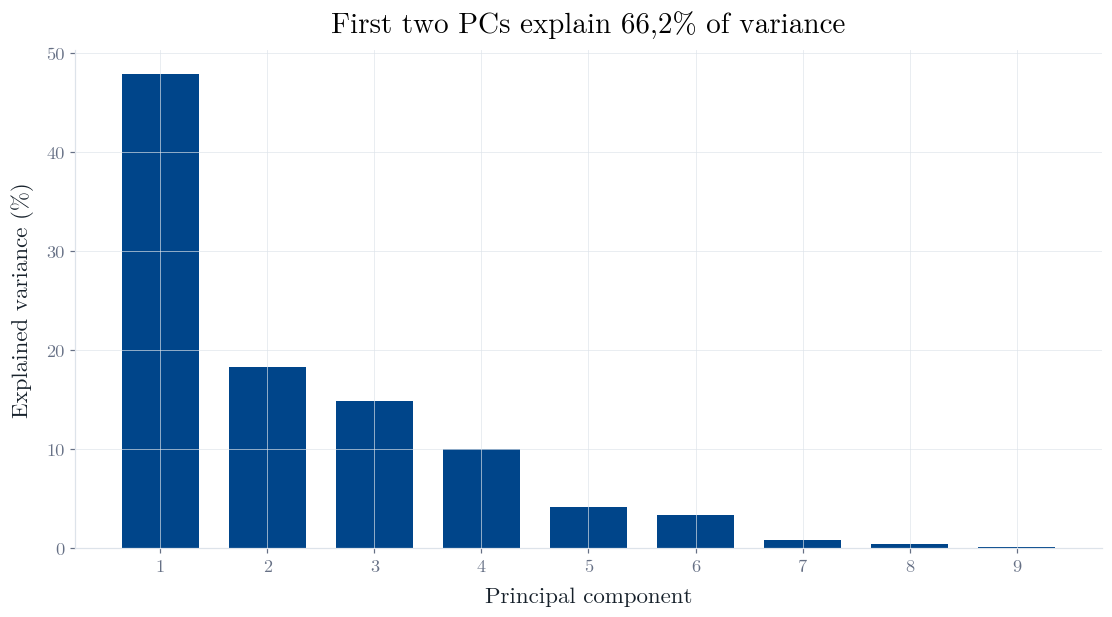

In [69]:
pca = PCA()
pca_scores = pca.fit_transform(X_scaled)
variance = pd.DataFrame({
    "component": np.arange(1, len(NUMERIC_FEATURES) + 1),
    "explained_variance_pct": 100 * pca.explained_variance_ratio_,
    "cumulative_variance_pct": 100 * np.cumsum(pca.explained_variance_ratio_),
})
display_es(variance, digits=2)
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=NUMERIC_FEATURES,
    columns=["PC1", "PC2"],
)
display_es(loadings.rename(index=FEATURE_LABELS), digits=3)

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
ax.bar(variance["component"], variance["explained_variance_pct"], color=BLUE, width=.72)
ax.set_xticks(variance["component"])
ax.set_ylim(bottom=0)
style_axis(ax, "Principal component", "Explained variance (%)")
ax.set_title(
    f"First two PCs explain {format_es(variance.loc[1, 'cumulative_variance_pct'], 1)}% of variance",
    fontsize=19, fontweight="bold", pad=12,
)
save_plot(fig, "09_pca_explained_variance")
plt.show()

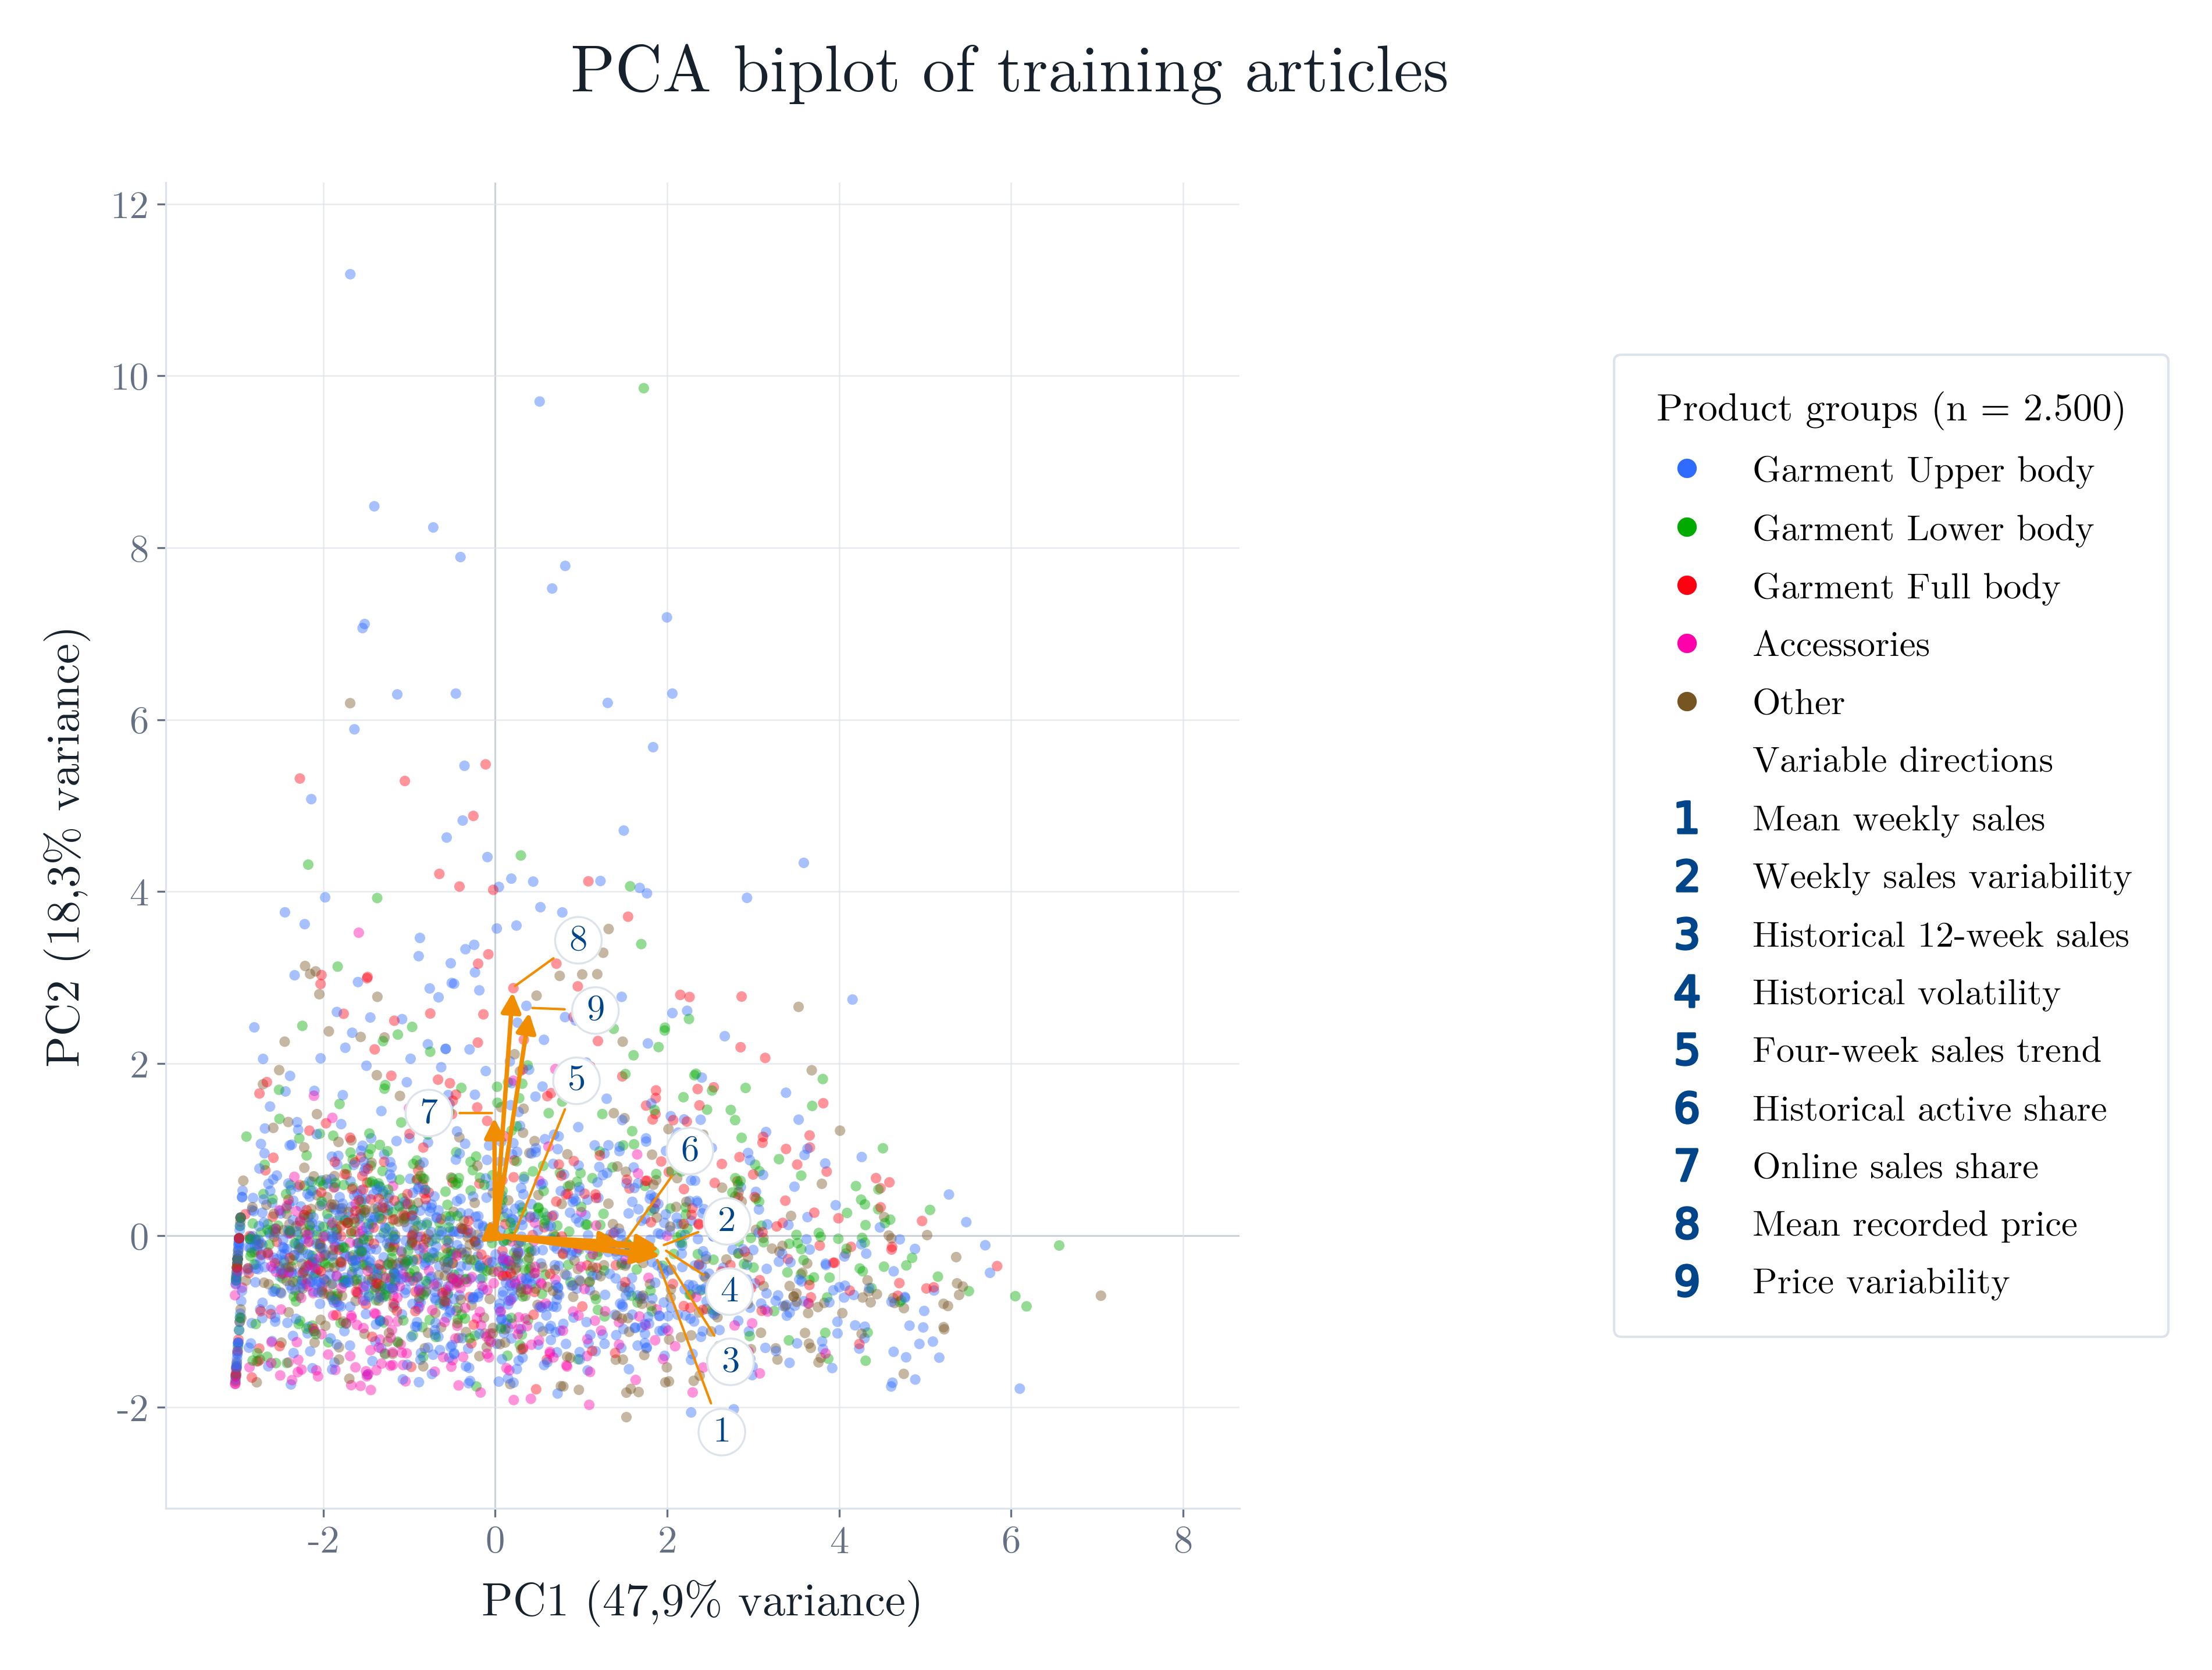

In [70]:
VIEW_N = min(2500, len(articles))
view_idx = np.sort(np.random.default_rng(SEED).choice(len(articles), VIEW_N, replace=False))
groups = articles["product_group_name"].fillna("Unknown").astype(str)
top_groups = groups.value_counts().head(4).index.tolist()
view_groups = groups.iloc[view_idx].where(groups.iloc[view_idx].isin(top_groups), "Other")
group_order = top_groups + (["Other"] if (~groups.iloc[view_idx].isin(top_groups)).any() else [])
# Additional colours are reserved for multi-category point clouds.
# Keep the same product-group mapping in PCA and t-SNE.
POINT_PALETTE = ["#2F6BFF", "#00AA00", "#FF0011", "#FF00AA", "#775522"]
group_colors = dict(zip(group_order, POINT_PALETTE))

# One biplot: article scores and variable directions in the same axes.
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 10))
fig.subplots_adjust(left=.09, right=.69, bottom=.13, top=.89)
cloud = pca_scores[view_idx, :2]
ax.scatter(
    cloud[:, 0], cloud[:, 1], s=19, alpha=.42,
    c=[group_colors[group] for group in view_groups],
    edgecolors="none", rasterized=True, zorder=2,
)
# Scores T and directions V form the rank-two approximation T @ V.T.
# One common scalar enlarges all directions, preserving angles and relative
# lengths. Arrow lengths are PCA coefficients, not variable correlations.
central_extent = np.quantile(np.abs(cloud), .98, axis=0)
arrow_scale = .80 * min(
    central_extent / np.maximum(np.abs(loadings.to_numpy()).max(axis=0), 1e-12)
)
tips = loadings.to_numpy() * arrow_scale
for tip in tips:
    ax.add_patch(FancyArrowPatch(
        (0, 0), tuple(tip), arrowstyle="-|>", mutation_scale=17,
        color=ORANGE, linewidth=1.8, zorder=4,
    ))

# Keep every sampled article visible, with equal units on both axes.
all_coordinates = np.vstack([cloud, tips, [[0, 0]]])
lo = all_coordinates.min(axis=0)
hi = all_coordinates.max(axis=0)
span = np.maximum(hi - lo, 1)
ax.set_xlim(lo[0] - .08 * span[0], hi[0] + .16 * span[0])
ax.set_ylim(lo[1] - .08 * span[1], hi[1] + .08 * span[1])
ax.set_aspect("equal", adjustable="box")
style_axis(
    ax,
    f"PC1 ({format_es(100 * pca.explained_variance_ratio_[0], 1)}% variance)",
    f"PC2 ({format_es(100 * pca.explained_variance_ratio_[1], 1)}% variance)",
)
ax.xaxis.label.set_fontsize(19)
ax.yaxis.label.set_fontsize(19)
ax.tick_params(axis="both", labelsize=16)
ax.axhline(0, color=MUTED, linewidth=.7, alpha=.5, zorder=1)
ax.axvline(0, color=MUTED, linewidth=.7, alpha=.5, zorder=1)
fig.suptitle("PCA biplot of training articles", fontsize=27,
             fontweight="bold", color=INK, y=.97)
fig.canvas.draw()

# Place short numeric identifiers in display coordinates. Nearby directions
# receive separated labels; leaders connect each label to its true arrow tip.
display_tips = ax.transData.transform(tips)
label_positions = display_tips.copy()
for side in [-1, 1]:
    indices = np.flatnonzero(np.where(tips[:, 0] < 0, -1, 1) == side)
    order = indices[np.argsort(display_tips[indices, 1])]
    if not len(order):
        continue
    desired = display_tips[order, 1].copy()
    separated = desired.copy()
    min_gap = 29 * fig.dpi / 72
    for j in range(1, len(order)):
        separated[j] = max(separated[j], separated[j - 1] + min_gap)
    separated -= np.mean(separated - desired)
    label_positions[order, 1] = separated
    label_positions[order, 0] += side * 27 * fig.dpi / 72

for i, (tip, location) in enumerate(zip(tips, label_positions), start=1):
    ax.annotate(
        str(i), xy=tip, xytext=ax.transData.inverted().transform(location),
        fontsize=15, color=BLUE, ha="center", va="center",
        bbox=dict(boxstyle="circle,pad=.20", fc="white", ec=GRID, lw=.8),
        arrowprops=dict(arrowstyle="-", color=ORANGE, lw=1,
                        shrinkA=3, shrinkB=1, connectionstyle="arc3"),
        annotation_clip=False, zorder=6,
    )

handles = [
    Line2D([], [], linestyle="none", marker="o", markersize=7,
           color=group_colors[group], label=group)
    for group in group_order
]
handles.append(Line2D([], [], linestyle="none", color="none",
                      label="Variable directions"))
handles += [
    Line2D([], [], linestyle="none", marker=f"${i}$", markersize=13,
           color=BLUE, label=FEATURE_LABELS[name])
    for i, name in enumerate(loadings.index, start=1)
]
fig.legend(
    handles=handles, loc="center left", bbox_to_anchor=(.71, .51),
    frameon=True, facecolor="white", edgecolor=GRID, fancybox=True,
    framealpha=1, fontsize=15, labelspacing=.70, borderpad=1,
    title=f"Product groups (n = {format_es(VIEW_N, 0)})", title_fontsize=16,
    handletextpad=.8,
)
save_plot(fig, "09_pca_biplot")
plt.show()


## 4. t-SNE projection

t-SNE is computed on the **same 2,500 (or fewer) articles** shown in the PCA article projection. It tries to keep nearby articles close in two dimensions. Its axes have no business units, and distances between distant groups or the apparent size of gaps should not be interpreted as evidence of distinct populations. The random seed and sample are fixed to make the picture reproducible.

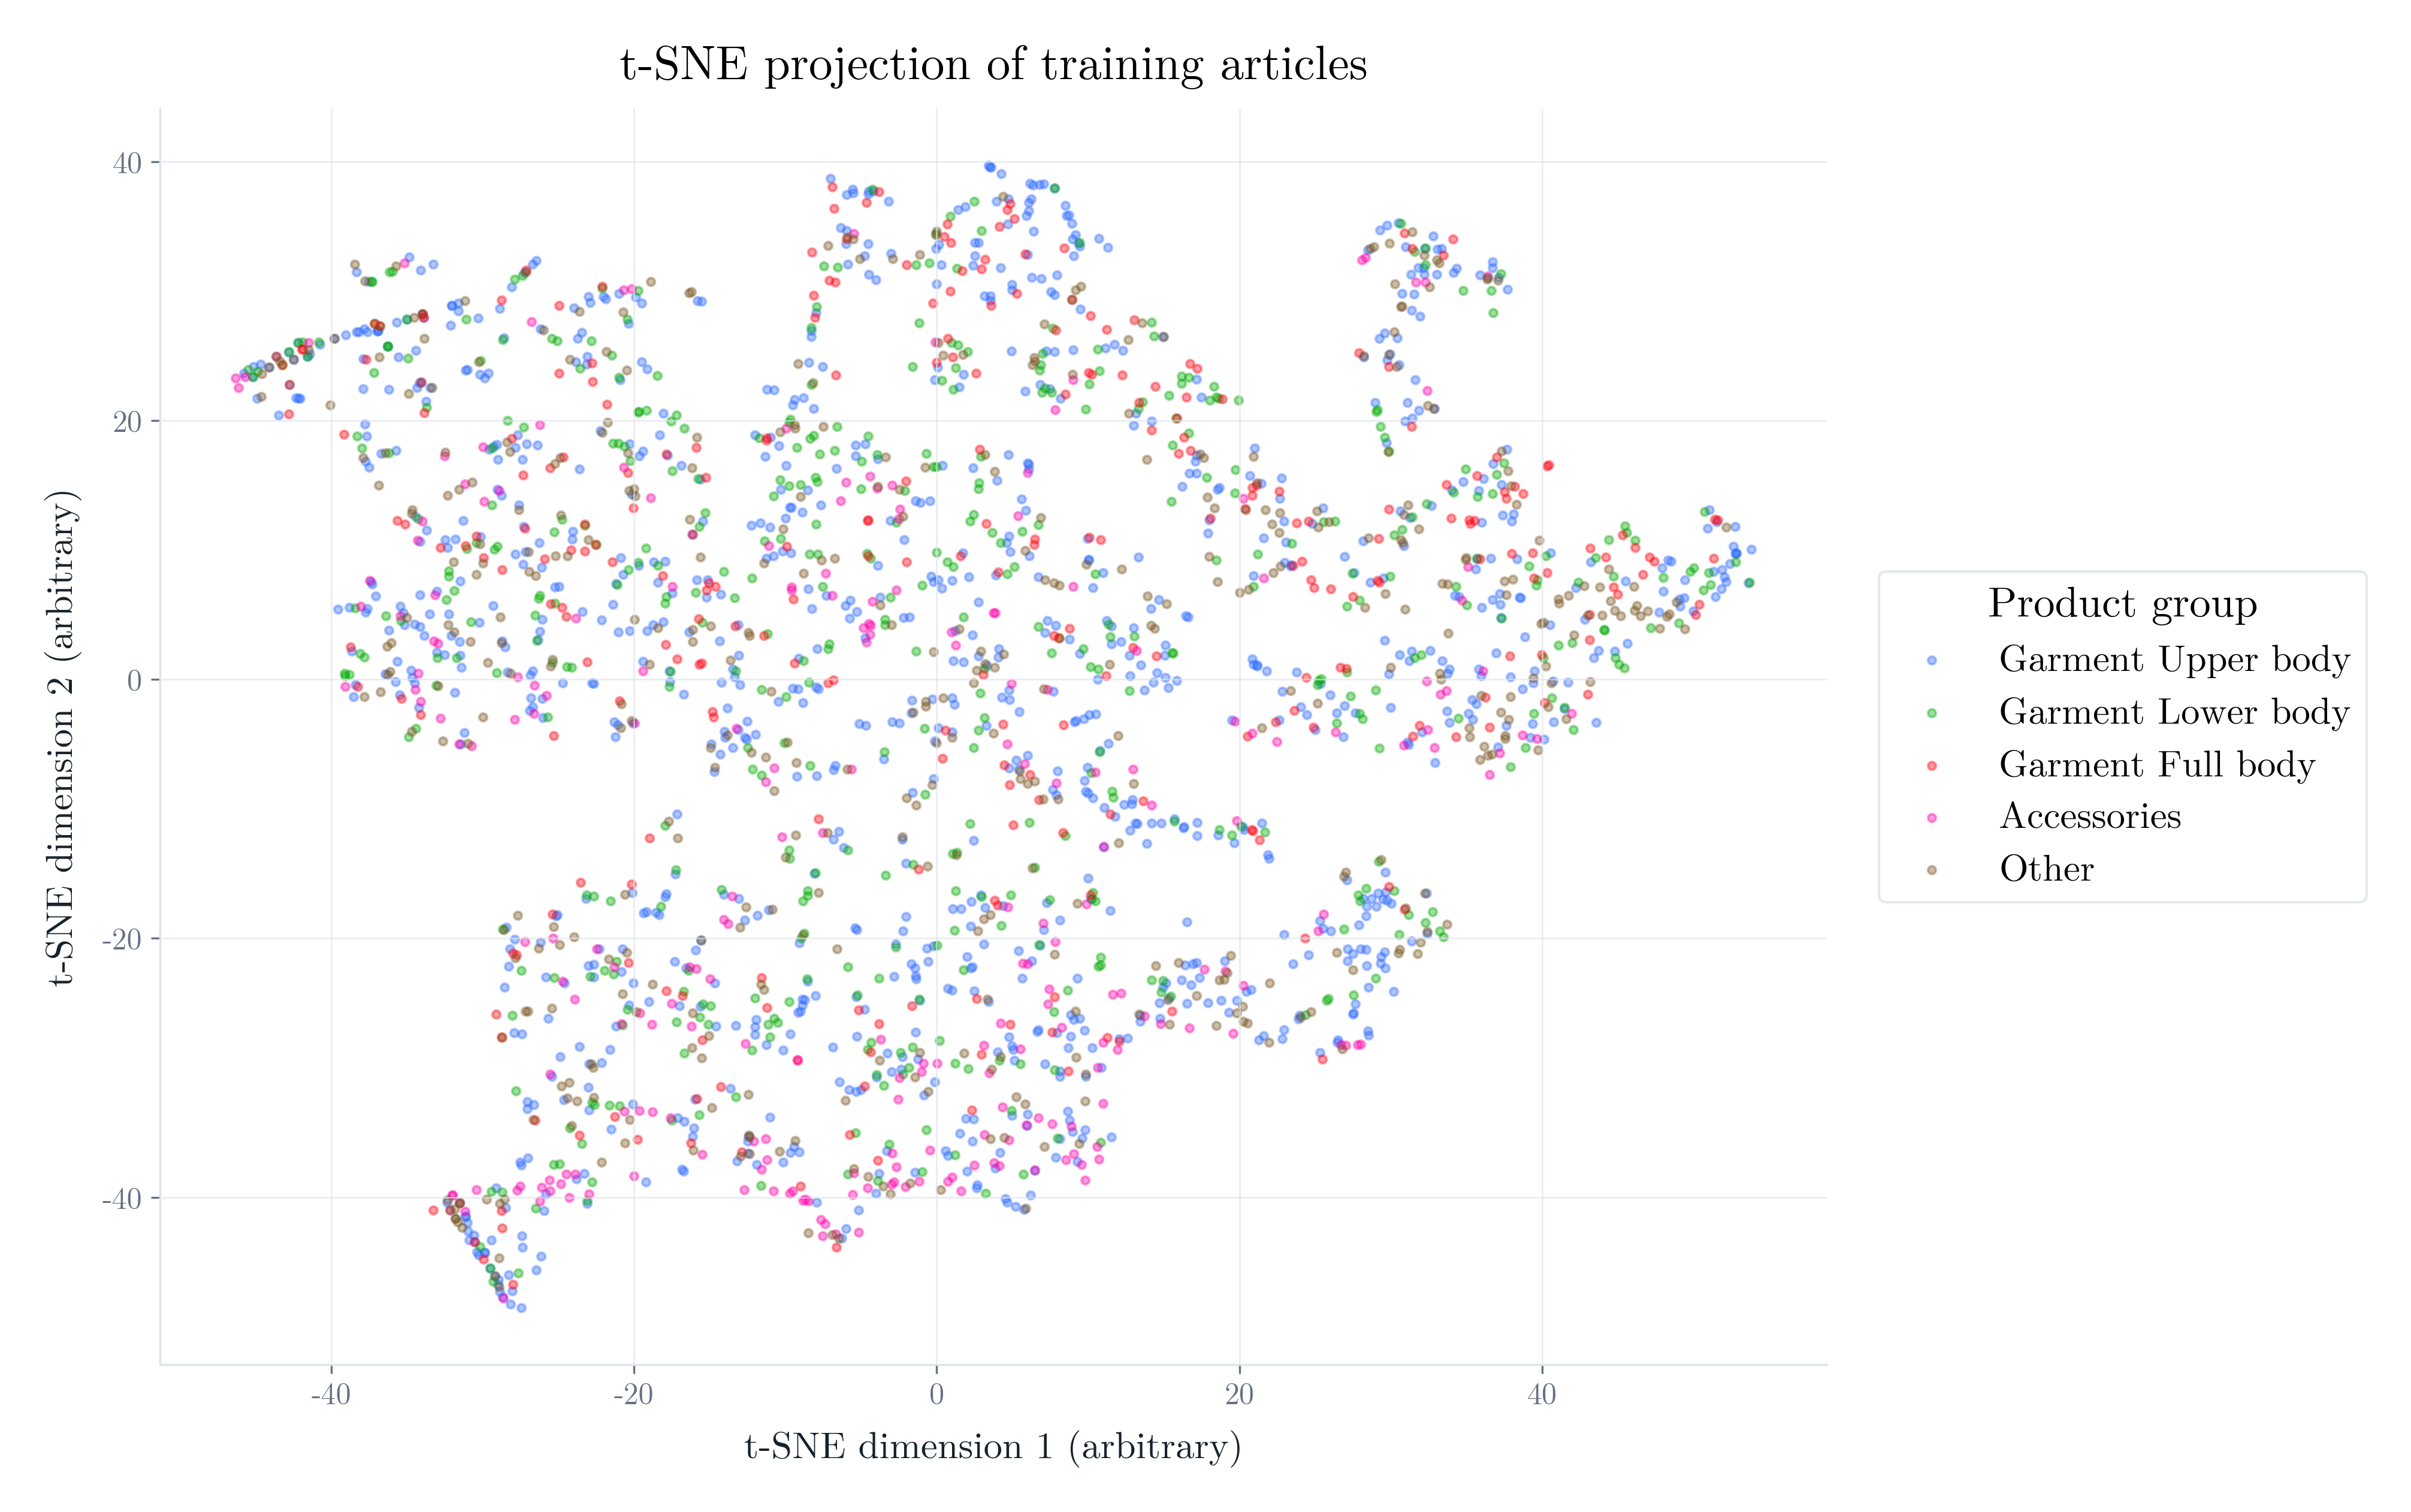

In [71]:
if VIEW_N < 100:
    raise ValueError("At least 100 articles are needed for this t-SNE display.")
tsne = TSNE(
    n_components=2, perplexity=min(30, (VIEW_N - 1) / 3),
    init="pca", learning_rate="auto", max_iter=750, random_state=SEED,
)
tsne_scores = tsne.fit_transform(X_scaled[view_idx])
fig, ax = plt.subplots(figsize=(13, 8), layout="constrained")
for group in group_order:
    mask = view_groups.to_numpy() == group
    ax.scatter(tsne_scores[mask, 0], tsne_scores[mask, 1], s=10, alpha=.38,
               color=group_colors[group], label=group, rasterized=True)
style_axis(ax, "t-SNE dimension 1 (arbitrary)", "t-SNE dimension 2 (arbitrary)")
ax.set_title("t-SNE projection of training articles",
             fontsize=19, fontweight="bold", pad=12)
ax.legend(loc="center left", bbox_to_anchor=(1.02, .5), frameon=True, facecolor="white", edgecolor=GRID,
          fancybox=True, fontsize=15, title="Product group", title_fontsize=17)
save_plot(fig, "09_tsne_training_articles")
plt.show()

## 5. K-means versus hierarchical clustering

Hierarchical clustering on all 77,000+ articles would be unnecessarily expensive. We therefore compare both methods on the **same fixed sample of up to 2,000 articles** and the same standardised numeric variables. For each candidate number of clusters, we report silhouette (higher means more separation relative to within-cluster distance) and the smallest cluster share. We choose the K-means cluster count by the highest sampled silhouette among solutions with no cluster smaller than 2%; this size rule avoids selecting tiny outlier groups. The hierarchical results are a sensitivity comparison, not a second full-population fit.

In [72]:
CLUSTER_SAMPLE_N = min(2000, len(articles))
if CLUSTER_SAMPLE_N < 100:
    raise ValueError("At least 100 training articles are needed for cluster comparison.")
cluster_idx = np.sort(np.random.default_rng(SEED + 1).choice(
    len(articles), CLUSTER_SAMPLE_N, replace=False,
))
X_sample = X_scaled[cluster_idx]
K_VALUES = range(2, min(7, CLUSTER_SAMPLE_N - 1))
comparison_rows = []
for k in K_VALUES:
    candidates = {
        "K-means": KMeans(n_clusters=k, n_init=10, random_state=SEED),
        "Hierarchical (Ward)": AgglomerativeClustering(n_clusters=k, linkage="ward"),
    }
    for method, estimator in candidates.items():
        labels = estimator.fit_predict(X_sample)
        counts = np.bincount(labels, minlength=k)
        comparison_rows.append({
            "method": method, "clusters": k,
            "silhouette": silhouette_score(X_sample, labels),
            "smallest_cluster_share": counts.min() / len(labels),
            "largest_cluster_share": counts.max() / len(labels),
            "sample_articles": len(labels),
        })
comparison = pd.DataFrame(comparison_rows)
display_es(comparison, digits=3)
kmeans_candidates = comparison.loc[comparison["method"].eq("K-means")]
eligible = kmeans_candidates.loc[kmeans_candidates["smallest_cluster_share"].ge(.02)]
selection_pool = eligible if not eligible.empty else kmeans_candidates
selection_note = ("minimum 2% cluster share enforced" if not eligible.empty
                  else "no candidate met the 2% size rule; best silhouette used")
chosen_k = int(selection_pool.sort_values(
    ["silhouette", "clusters"], ascending=[False, True],
).iloc[0]["clusters"])
print("Selected K-means cluster count:", chosen_k, "—", selection_note)

,method,clusters,silhouette,smallest_cluster_share,largest_cluster_share,sample_articles
0,K-means,2,"0,345","0,38","0,62",2.000
1,Hierarchical (Ward),2,"0,252","0,377","0,624",2.000
2,K-means,3,"0,357","0,044","0,598",2.000
3,Hierarchical (Ward),3,"0,223","0,229","0,395",2.000
4,K-means,4,"0,245","0,038","0,399",2.000
5,Hierarchical (Ward),4,"0,231","0,032","0,377",2.000
6,K-means,5,"0,249","0,038","0,308",2.000
7,Hierarchical (Ward),5,"0,216","0,032","0,377",2.000
8,K-means,6,"0,262","0,037","0,286",2.000
9,Hierarchical (Ward),6,"0,22","0,032","0,283",2.000


Selected K-means cluster count: 3 — minimum 2% cluster share enforced


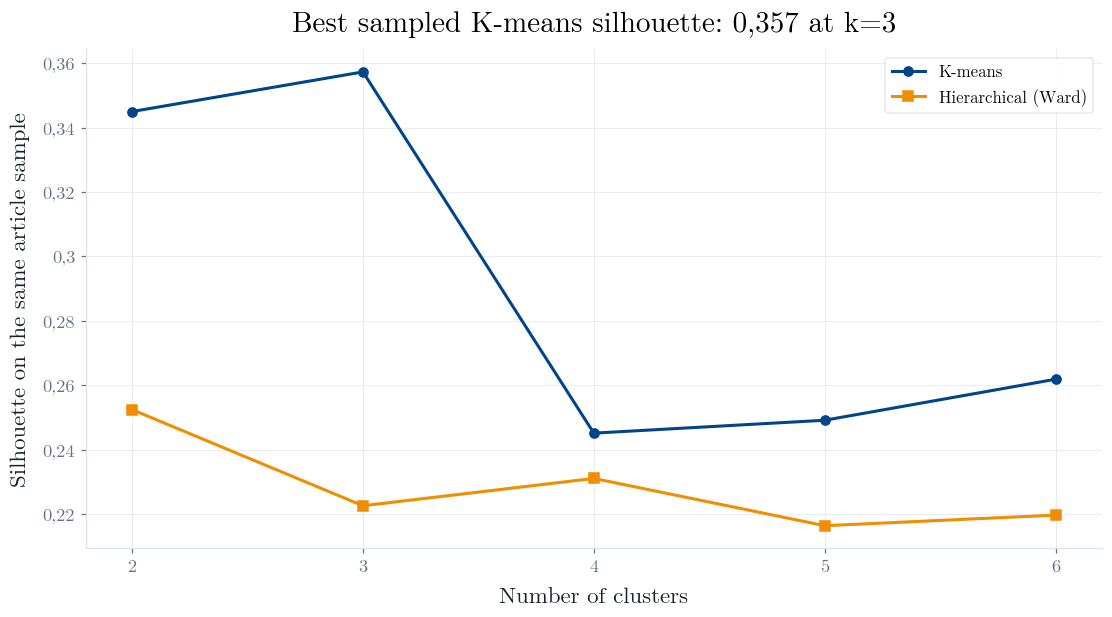

In [73]:
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
for method, color, marker in [
    ("K-means", BLUE, "o"), ("Hierarchical (Ward)", ORANGE, "s"),
]:
    rows = comparison.loc[comparison["method"].eq(method)].sort_values("clusters")
    ax.plot(rows["clusters"], rows["silhouette"], marker=marker,
            linewidth=2, color=color, label=method)
ax.set_xticks(list(K_VALUES))
style_axis(ax, "Number of clusters", "Silhouette on the same article sample")
ax.set_title(
    f"Best sampled K-means silhouette: {format_es(selection_pool.sort_values('silhouette').iloc[-1]['silhouette'], 3)} at k={chosen_k}",
    fontsize=19, fontweight="bold", pad=12,
)
ax.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=11)
save_plot(fig, "09_cluster_method_comparison")
plt.show()

## 6. Full-population clusters and seed stability

We now refit **only the selected K-means setting** on all training articles. The cluster numbers themselves have no order: cluster 0 is simply a label. To check whether the sampled K-means solution is highly sensitive to its random starting point, we fit it on the **same comparison sample** under five seeds and compute pairwise adjusted Rand indices (ARI). ARI equals 1 for identical partitions up to label renaming; this seed check does not establish stability over future seasons.

In [74]:
final_kmeans = KMeans(n_clusters=chosen_k, n_init=10, random_state=SEED)
full_labels = final_kmeans.fit_predict(X_scaled)
cluster_sizes = pd.Series(full_labels).value_counts().sort_index()
display_es(pd.DataFrame({
    "articles": cluster_sizes,
    "share_pct": (100 * cluster_sizes / len(articles)).round(2),
}).rename_axis("cluster"), digits=2)

seed_labels = [KMeans(n_clusters=chosen_k, n_init=10, random_state=seed)
               .fit_predict(X_sample) for seed in range(SEED, SEED + 5)]
stability_ari = [
    adjusted_rand_score(seed_labels[i], seed_labels[j])
    for i in range(len(seed_labels)) for j in range(i + 1, len(seed_labels))
]
print("Sampled K-means ARI across seeds: minimum", f"{min(stability_ari):.3f}",
      "; median", f"{np.median(stability_ari):.3f}")

,articles,share_pct
cluster,,
0,27.139,"35,08"
1,34.107,"44,09"
2,16.111,"20,83"


Sampled K-means ARI across seeds: minimum 0.982 ; median 0.985


## 7. Cluster profiles, limitations and saved summary

The table uses **raw, interpretable units** to describe each group. Product categories were not clustering inputs, so their frequencies offer an independent description of the groups. The heatmap expresses each cluster median's distance from the overall training median in units of the overall interquartile range (IQR); it is not a causal contribution or a supervised feature importance.

The final cell saves only aggregate scores and profiles in `results/metrics`. It does **not** export one row per article or change the processed publication. These groups describe articles with observed training sales and different lengths of observed history. They do not show what would happen for new articles without history, prove that categories cause sales, or validate a future sales forecast.

,articles,median_weekly_sales,median_sales_variability,median_12w_sales,median_active_share,median_online_share,median_recorded_price,median_observed_weeks,most_common_product_group,most_common_group_share_pct,article_share_pct
cluster,,,,,,,,,,,
0,27.139,"4,286","3,857","4,1","0,708","0,861","0,024",21,Garment Upper body,"43,539","35,083"
1,34.107,"1,5","0,707","0,417","0,214",1,"0,018",5,Garment Upper body,"38,925","44,09"
2,16.111,"22,719","23,646","18,889","0,728","0,761","0,024",27,Garment Upper body,"41,22","20,827"


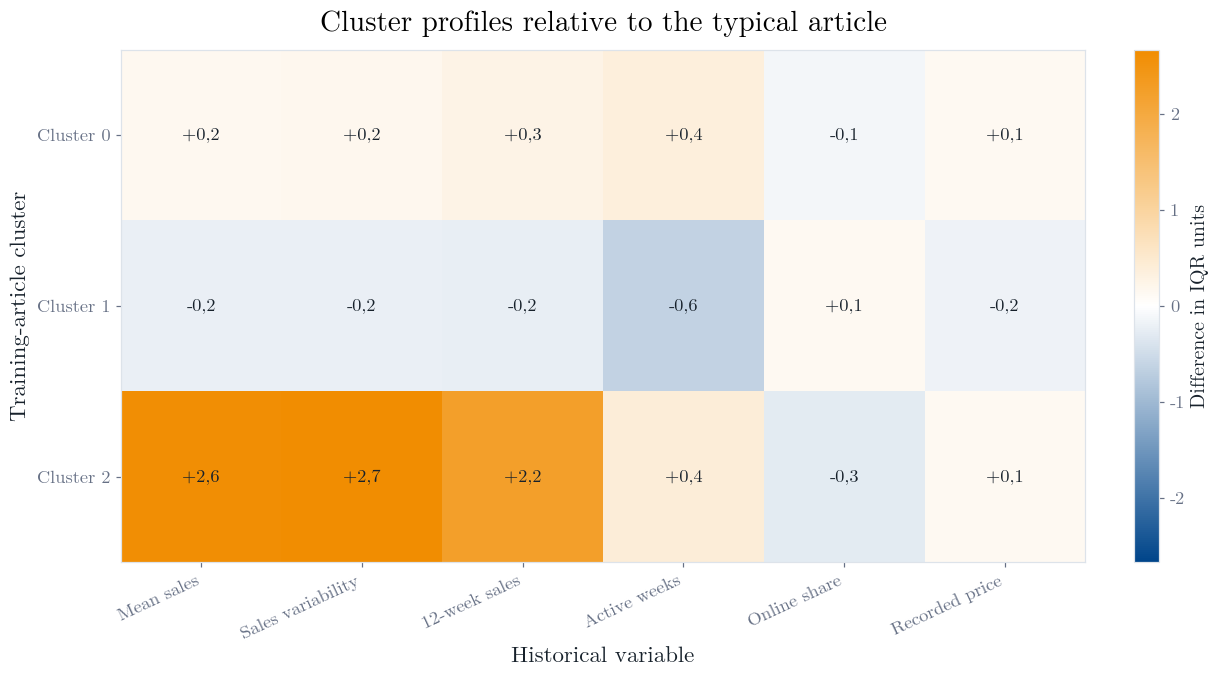

In [75]:
profiled = articles.copy()
profiled["cluster"] = full_labels
profile_columns = [
    "mean_current_week_sales", "std_current_week_sales", "mean_12w_sales",
    "historical_active_share", "mean_online_share", "mean_price",
]
profiles = profiled.groupby("cluster").agg(
    articles=("article_id", "size"),
    median_weekly_sales=("mean_current_week_sales", "median"),
    median_sales_variability=("std_current_week_sales", "median"),
    median_12w_sales=("mean_12w_sales", "median"),
    median_active_share=("historical_active_share", "median"),
    median_online_share=("mean_online_share", "median"),
    median_recorded_price=("mean_price", "median"),
    median_observed_weeks=("article_weeks", "median"),
)
category_share = pd.crosstab(
    profiled["cluster"], profiled["product_group_name"].fillna("Unknown"),
    normalize="index",
)
profiles["most_common_product_group"] = category_share.idxmax(axis=1)
profiles["most_common_group_share_pct"] = 100 * category_share.max(axis=1)
profiles["article_share_pct"] = 100 * profiles["articles"] / len(profiled)
display_es(profiles, digits=3)

cluster_medians = profiled.groupby("cluster")[profile_columns].median()
overall_median = profiled[profile_columns].median()
overall_iqr = (profiled[profile_columns].quantile(.75)
               - profiled[profile_columns].quantile(.25)).replace(0, np.nan)
relative_profiles = ((cluster_medians - overall_median) / overall_iqr).fillna(0)
largest_contrast = relative_profiles.abs().max().idxmax()
bound = max(1.0, float(relative_profiles.abs().to_numpy().max()))
fig, ax = plt.subplots(figsize=(11, max(6.0, chosen_k * .85 + 3.5)), layout="constrained")
from matplotlib.colors import LinearSegmentedColormap
etsit_diverging = LinearSegmentedColormap.from_list(
    "etsit_blue_white_orange", [BLUE, "#FFFFFF", ORANGE]
)
im = ax.imshow(relative_profiles.to_numpy(), aspect="auto", cmap=etsit_diverging,
               vmin=-bound, vmax=bound)
short_labels = ["Mean sales", "Sales variability", "12-week sales",
                "Active weeks", "Online share", "Recorded price"]
ax.set_xticks(np.arange(len(profile_columns)), short_labels,
              rotation=25, ha="right", fontsize=12)
ax.set_yticks(np.arange(chosen_k), [f"Cluster {k}" for k in relative_profiles.index])
ax.set_xlabel("Historical variable", fontsize=15, fontweight="bold", color=INK)
ax.set_ylabel("Training-article cluster", fontsize=15, fontweight="bold", color=INK)
for row in range(chosen_k):
    for col in range(len(profile_columns)):
        value = relative_profiles.iat[row, col]
        ax.text(col, row, ("+" if value > 0 else "") + format_es(value, 1), ha="center", va="center",
                fontsize=12, color="white" if value < -bound * .55 else INK)
colorbar = fig.colorbar(im, ax=ax, label="Difference from overall median (overall IQRs)",
                        format=FuncFormatter(lambda value, _: format_es(value, 1)))
colorbar.ax.tick_params(labelsize=12)
colorbar.set_label("Difference in IQR units", fontsize=13)
ax.set_title("Cluster profiles relative to the typical article",
             fontsize=19, fontweight="bold", pad=12)
save_plot(fig, "09_cluster_profiles")
plt.show()

In [76]:
selected_sample_row = kmeans_candidates.loc[
    kmeans_candidates["clusters"].eq(chosen_k)
].iloc[0]
best_hierarchical = comparison.loc[
    comparison["method"].eq("Hierarchical (Ward)")
].sort_values("silhouette", ascending=False).iloc[0]
record = {
    "publication_run": run_dir.name,
    "clustering_file_sha256": digest.hexdigest(),
    "source_partition": "train only",
    "future_targets_used": False,
    "unit": "article",
    "articles": len(articles),
    "numeric_features": NUMERIC_FEATURES,
    "log1p_features": LOG_FEATURES,
    "asinh_features": ["mean_sales_trend_4w"],
    "imputation": "per-feature median of training articles",
    "scaling": "standard score on training articles",
    "random_seed": SEED,
    "pca_first_two_variance_share": float(pca.explained_variance_ratio_[:2].sum()),
    "tsne_sample_articles": VIEW_N,
    "cluster_comparison_sample_articles": CLUSTER_SAMPLE_N,
    "cluster_selection_rule": selection_note,
    "selected_kmeans_clusters": chosen_k,
    "selected_kmeans_sample_silhouette": float(selected_sample_row["silhouette"]),
    "best_hierarchical_sample_k": int(best_hierarchical["clusters"]),
    "best_hierarchical_sample_silhouette": float(best_hierarchical["silhouette"]),
    "kmeans_seed_ari_min": float(min(stability_ari)),
    "kmeans_seed_ari_median": float(np.median(stability_ari)),
    "comparison": comparison.to_dict("records"),
}
METRIC_DIR.mkdir(parents=True, exist_ok=True)
metrics_path = METRIC_DIR / f"09_unsupervised_{run_dir.name}.json"
profiles_path = METRIC_DIR / f"09_unsupervised_profiles_{run_dir.name}.csv"
metrics_path.write_text(json.dumps(record, indent=2) + "\n", encoding="utf-8")
profiles.to_csv(profiles_path, index_label="cluster")
print("Saved:", metrics_path)
print("Saved:", profiles_path)

display(Markdown(
    f"**Interpretation.** {format_es(len(articles), 0)} training articles were described without future targets. "
    f"K-means with {chosen_k} groups reached a sampled silhouette of "
    f"{format_es(selected_sample_row['silhouette'], 3)}; the best hierarchical sample reached "
    f"{format_es(best_hierarchical['silhouette'], 3)}. The largest raw-profile contrast is in "
    f"**{FEATURE_LABELS[largest_contrast]}**. Seed stability on the same sample has "
    f"median ARI {format_es(np.median(stability_ari), 3)}. These are descriptive segments "
    "of previously sold articles, not evidence of future predictive performance."
))

Saved: c:\Iratxe\UPM\prdl y mllb\fashion-demand-ml\results\metrics\09_unsupervised_20261027T145552-5a1ac59a.json
Saved: c:\Iratxe\UPM\prdl y mllb\fashion-demand-ml\results\metrics\09_unsupervised_profiles_20261027T145552-5a1ac59a.csv


**Interpretation.** 77.357 training articles were described without future targets. K-means with 3 groups reached a sampled silhouette of 0,357; the best hierarchical sample reached 0,252. The largest raw-profile contrast is in **Weekly sales variability**. Seed stability on the same sample has median ARI 0,985. These are descriptive segments of previously sold articles, not evidence of future predictive performance.

## 8. What the saved results mean

The following interpretation refers to the saved publication `20261027T145552-5a1ac59a`. It describes the observed **training articles**, not customers or future forecasts. If the source publication or the clustering settings change, rerun the analysis and revise these figures.

**PCA.** The first two components retain **66.2%** of the variation in the nine transformed and standardised numeric inputs. The article projection therefore gives a useful two-dimensional overview, but about one third of the variation remains outside its axes. The numbered arrows in the biplot show which variables align with PC1 and PC2; the external legend identifies all nine inputs. These directions are not effects on future sales.

**t-SNE.** The plot uses the same fixed sample of 2,500 articles as the PCA article projection. Nearby points have similar numeric histories under this projection. The apparent gaps and distances between far-apart regions are not a statistical test of separate populations.

**Cluster choice.** On the same 2,000-article comparison sample, the selected three-group K-means solution has silhouette **0.357**, compared with **0.252** for the best tested Ward hierarchical setting (two groups). This is moderate descriptive separation, not a prediction score. On that sample, changing K-means' random seed gives a median adjusted Rand index of **0.985**: assignments are fairly stable to these starts. The full article table is then clustered separately with the chosen K-means setting.

**What each full-data group contains.** Cluster numbers are arbitrary labels; the descriptions below come from medians in `results/metrics/09_unsupervised_profiles_20261027T145552-5a1ac59a.csv`.

| Cluster | Articles | Share | Typical recorded weekly sales | Observed active-week share | Interpretation |
|---|---:|---:|---:|---:|---|
| 0 | 27,139 | 35.1% | 4.29 | 70.8% | Moderate sales with relatively frequent activity. |
| 1 | 34,107 | 44.1% | 1.50 | 21.4% | Lower and less regular recorded sales; shorter observed histories are common. |
| 2 | 16,111 | 20.8% | 22.72 | 72.8% | Higher recorded sales and greater week-to-week variability. |

All three groups have **Garment Upper body** as their most common broad product group. The clustering inputs were numeric behaviour summaries, so these groups should not be described as garment categories. Because the source table includes articles with observed training sales, the findings do not establish how a new article without history would be assigned or how well next week's demand would be predicted.